In [12]:
import numpy as np
import pandas as pd
from matplotlib import pyplot
import os

import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import plot_util as putil
import multi_fgl_utils as util
import dio3

In [25]:
script_fn = 'fermi_multiclass/notebooks/compare_probs.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}


# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL_DR3'
if cat_name == '4FGL-DR4':
    if 0:
        baseline_case = '4FGL-DR4_GMM_RF'
        case = '4FGL-DR4_GMM_RF' # '4FGL_DR4_2class', '4FGL_DR4_RF_RF'
        case_w = '4FGL-DR4_GMM_RF_w' # '4FGL_DR4_2class', '4FGL_DR4_RF_RF'
    else:
        baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
        baseline_case_w = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
        case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
        case_w = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_NN'
if cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_3class_RF'
    if 0:
        case = '4FGL-DR3_3class_RF'
        baseline_case_w = '4FGL-DR3_3class_RF'
        case_w = '4FGL-DR3_3class_spec_features_RF'
    else:
        #case = '4FGL-DR3_3class_RF'
        case = '4FGL-DR3_3class_spec_features_RF'
        baseline_case_w = '4FGL-DR3_3class_Toby'
        case_w = '4FGL-DR3_3class_Toby' # '4FGL_DR4_2class', '4FGL_DR4_RF_RF'
    
baseline = (case == baseline_case)
root_folder = '../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)

cdict_w = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_case_w, 
                             case=case_w, 
                             folder=config_folder)

folder = '../results/%s_probabilistic_catalogs/' % util.get_cat_descr(cdict)
folder_w = '../results/%s_probabilistic_catalogs/' % util.get_cat_descr(cdict_w)

plots_folder = '../plots/comparisons/'
if case_w.find('Toby') > -1:
    plots_folder += 'compare_with_Toby/'
if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)
    
paper_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/3_cov_shift_paper\
/cov_shift_paper_main/plots/prob_comparisons/'
save_plots = 1
save_png = 1
copy2tex = 0
rel_std = 0

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)

class_name = cdict.get('class_name', 'CLASS1')
#folder = '../results/%s_probabilistic_catalogs/' % util.get_cat_descr(cdict)
cat_fn = folder + util.get_cat_descr(cdict) + '_prob_cat.csv'
#folder = '../results/%s_probabilistic_catalogs/' % util.get_cat_descr(cdict_w)
cat_info_fn = cat_fn.replace('prob_cat.csv', 'summary.csv')
wcat_fn = folder_w + util.get_cat_descr(cdict_w) + '_prob_cat.csv'

cat = pd.read_csv(cat_fn, index_col=0)
cat_info = pd.read_csv(cat_info_fn, index_col=0, dtype=str)
wcat = pd.read_csv(wcat_fn, index_col=0)
if case_w.find('Toby') > -1:
    nmax = len(wcat.index[0])
    cat.index = [x[:17] for x in cat.index]
    xdf.index = [x[:17] for x in xdf.index]
    


# in general take the intersection of sources
snames = set(cat.index).intersection(wcat.index)
index = list(snames)
cat = cat.loc[index]
wcat = wcat.loc[index]
xdf = xdf.loc[index]

if case_w.find('Toby') > -1:
    cats = {'Dima': cat, 'Toby': wcat}
    compare1 = [['Dima', 'SVC'], ['Toby', 'SVC']]
    compare2 = [['Dima', 'SVC'], ['Dima', 'RF']]
    compare3 = [['Toby', 'SVC'], ['Dima', 'RF']]
    compare4 = [['Dima', 'NN'], ['Dima', 'RF']]
    show = [compare1, compare2, compare3, compare4]
    wlabel = {'Dima': 'Dima', 'Toby': 'Toby'}
elif case_w.find('_NN') > -1:
    cats = {'RF': cat, 'NN': wcat}
    compare1 = [['RF', 'RF'], ['NN', 'NN']]
    show = [compare1]
    wlabel = {'RF': '', 'NN': ''}
elif case_w.find('_w') == -1:
    cats = {'Full': cat, 'Spec': wcat}
    compare1 = [['Full', 'RF'], ['Spec', 'RF']]
    compare2 = [['Full', 'SVC'], ['Spec', 'SVC']]
    compare3 = [['Spec', 'RF'], ['Spec', 'SVC']]
    show = [compare1, compare2, compare3]
    wlabel = {'Full': 'Full', 'Spec': 'Spec'}
    
else:
    cats = {'weighted': wcat, 'unweighted': cat}
    compare1 = [['weighted', 'RF'], ['unweighted', 'RF']]
    compare2 = [['weighted', 'NN'], ['unweighted', 'NN']]
    compare3 = [['unweighted', 'RF'], ['unweighted', 'NN']]
    compare4 = [['weighted', 'RF'], ['weighted', 'NN']]
    show = [compare1, compare2, compare3, compare4]
    wlabel = {'weighted': 'w', 'unweighted': ''}

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
nsrc_df = util.nsrc_dict2df(nsrc_dict)

#show = [compare1, compare4]
#show = [compare3, compare4]

single_plot_pars = {}
print(case_w, show)

4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_NN [[['RF', 'RF'], ['NN', 'NN']]]


In [35]:
if 0:
    nodes = range(1, 4) # hack for comparision with Toby!!!
else:
    nodes = list(cat_info.index)

ncols = 3
nrows = int(np.ceil(len(nodes) / ncols))

fig_height = 3 * nrows + 2   # height in inches
fig_width = 3 * ncols + 6  # width in inches
#all_plots_pars = {'axes.titlesize':18}
all_plots_pars = {'bottom':0.12, 'left':0.12, 'right':0.97, 'top':0.88}
all_plots_pars.update({'axes.labelsize': 14,
                      'axes.titlesize': 14,  #title
                      'legend.fontsize': 10,
                      'xtick.labelsize':12, #ticks
                      'ytick.labelsize':12,}
                     )
fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
#all_plots_pars['font.size'] = 11
#all_plots_pars['legend.fontsize'] = 10

putil.setup_figure_pars(pars_dict=all_plots_pars)
#putil.setup_figure_pars(pars_dict=single_plot_pars)

0

save figure to file: ../plots/comparisons//4FGL-DR4_prob_comparisons_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_NN_unas.pdf
save figure to file: ../plots/comparisons//4FGL-DR4_prob_comparisons_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_NN_unas.png


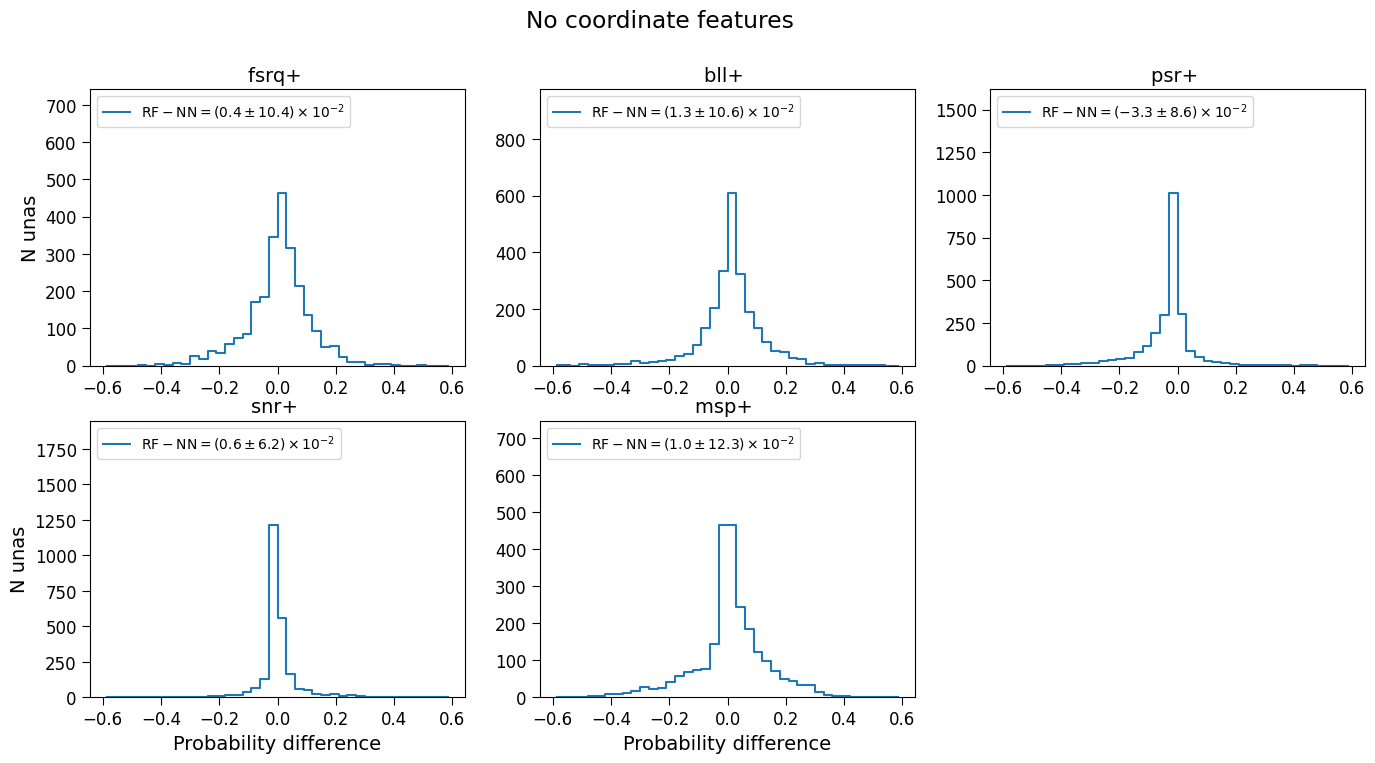

In [36]:
epsilon = 1.e-15
plot_unas = 1
comp_str = '%s_%s' % (case, case_w)
if plot_unas:
    plot_mask = (cat['CLASS1'] == 'unas')
    comp_str += '_unas'
else:
    plot_mask = (cat['CLASS1'] != 'unas')
    comp_str += '_assoc'
    
if rel_std:
    maxv = 4
    npts = int(maxv * 10) + 1
    bins = np.linspace(-maxv, maxv, npts)
else:
    #maxv = 0.4
    maxv = 0.6
    bins = np.linspace(-maxv, maxv, 41)
xs = (bins[1:] + bins[:-1]) / 2.

lss = ['-', '--', '-.', ':']

pyplot.figure()
for ind, node in enumerate(nodes[:]):
    vmax = 0.
    classes = cat_info['Physical classes'].loc[node].split(', ')
    max_class = util.get_max_class(classes, nsrc_df)
    ax = pyplot.subplot(nrows, ncols, ind + 1)
    for ic, comp in enumerate(show):
        vs = []
        stds = []
        label = r'$\rm '
        for i in range(2):
            if i == 1:
                label += ' - '
            wst, alg = comp[i]
            clm = '%i_%s' % (node, alg)
            vs.append(cats[wst][clm][plot_mask])
            if clm + '_std' in cats[wst].columns:
                std = cats[wst][clm + '_std'][plot_mask]
                
            else:
                std = 0.01 * cats[wst][clm][plot_mask] # placeholder
            stds.append(std)
            label += '%s%s' % (wlabel[wst], alg)
        pvs = vs[0] - vs[1]
        if rel_std:
            std_av = np.sqrt(stds[0]**2 + stds[1]**2) / np.sqrt(2.) + epsilon
            pvs /= std_av
            label += ' = (%.2f \pm %.2f)$' % (np.mean(pvs), np.std(pvs))
        else:
            #label += ' = (%.2f \pm %.2f)\%%$' % (np.mean(pvs)*100, np.std(pvs)*100)
            if np.around(np.mean(pvs)*1000) == 0.:
                label += ' = (%.2f \pm %.2f)\\times 10^{-2}$' % (np.mean(pvs)*100, np.std(pvs)*100)
            else:
                label += ' = (%.1f \pm %.1f)\\times 10^{-2}$' % (np.mean(pvs)*100, np.std(pvs)*100)
        label = label.replace('_', '\\_')
        hvs = np.histogram(pvs, bins=bins)[0]
        vmax = np.maximum(vmax, np.max(hvs))
        pyplot.plot(xs, hvs, drawstyle='steps-mid', ls=lss[ic%len(lss)], label=label)
    #pyplot.legend(fontsize=12, labelspacing=0.3, loc='upper left')
    pyplot.legend(labelspacing=0.1, loc='upper left')
    pyplot.title('%s+ ' % max_class)
    pyplot.ylim(0, vmax*1.6)
    if ind >= ncols * (nrows - 1):# or nrows == 1:
        if rel_std:
            pyplot.xlabel('Probability difference / std')
        else:
            pyplot.xlabel('Probability difference')
        
    if ind < ncols * (nrows - 1) and False:
        ax.axes.xaxis.set_visible(False)
    if ind % ncols != 0 and False:
        ax.axes.yaxis.set_visible(False)
    if ind % ncols == 0:
        if plot_unas:
            pyplot.ylabel('N unas')
        else:
            pyplot.ylabel('N assoc')

if cdict['features'] == 'no_coord_features':
    pyplot.suptitle('No coordinate features')
elif cdict['features'] == 'spec_features':
    pyplot.suptitle('Spectral and variability features')

fn = '%s/%s_prob_comparisons_%s.pdf' % (plots_folder, cat_name, comp_str)
if save_plots:
    fn = '%s/%s_prob_comparisons_%s.pdf' % (plots_folder, cat_name, comp_str)
    if rel_std:
        fn = '%s/%s_prob_comparisons_rel_%s.pdf' % (plots_folder, cat_name, comp_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, paper_folder)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)


In [ ]:
cdict['features'] == 'no_coord_features'